In [2]:
from pathlib import Path
import requests

BASE_URL = "https://ftp.ebi.ac.uk/biostudies/fire/S-BIAD/047/S-BIAD1047/Files/Images"
DATA_DIR = Path("data/raw/Study_28")

DATA_DIR.mkdir(parents=True, exist_ok=True)

filenames = [
    "image_2488_PC_z0.ome.tiff",
    "image_2488_Nucleus.ome.tiff"
]

for filename in filenames:
    url = f"{BASE_URL}/Study_28/{filename}"
    destination = DATA_DIR / filename

    if destination.exists():
        print(f"Already downloaded: {filename}")
        continue

    response = requests.get(url, timeout=(15, 120), stream=True)
    response.raise_for_status()

    with open(destination, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print(f"Downloaded: {filename}")

Downloaded: image_2488_PC_z0.ome.tiff
Downloaded: image_2488_Nucleus.ome.tiff


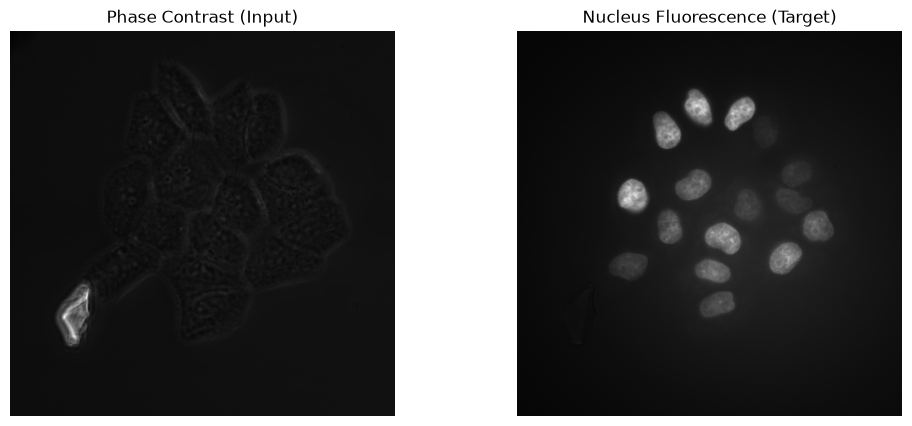

PC: (2048, 2048) uint16
Nucleus: (2048, 2048) uint16


In [3]:
import tifffile
import matplotlib.pyplot as plt

pc = tifffile.imread(DATA_DIR / "image_2488_PC_z0.ome.tiff")
nucleus = tifffile.imread(DATA_DIR / "image_2488_Nucleus.ome.tiff")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(pc, cmap="gray")
axes[0].set_title("Phase Contrast (Input)")

axes[1].imshow(nucleus, cmap="gray")
axes[1].set_title("Nucleus Fluorescence (Target)")

for ax in axes:
    ax.axis("off")

plt.show()

print("PC:", pc.shape, pc.dtype)
print("Nucleus:", nucleus.shape, nucleus.dtype)

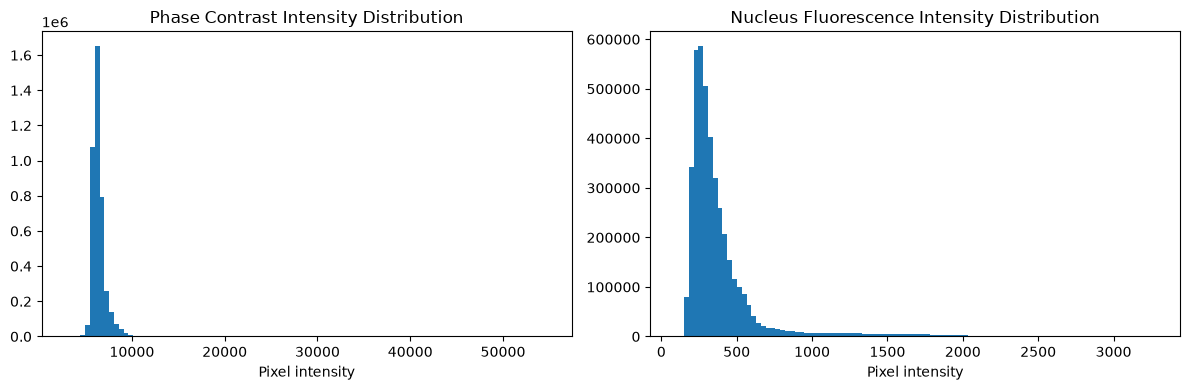

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(pc.ravel(), bins=100)
axes[0].set_title("Phase Contrast Intensity Distribution")
axes[0].set_xlabel("Pixel intensity")

axes[1].hist(nucleus.ravel(), bins=100)
axes[1].set_title("Nucleus Fluorescence Intensity Distribution")
axes[1].set_xlabel("Pixel intensity")

plt.tight_layout()
plt.show()

In [5]:
for name, image in [("PC", pc), ("Nucleus", nucleus)]:
    print(f"\n{name}")
    print("Shape:", image.shape)
    print("Dtype:", image.dtype)
    print("Min:", image.min())
    print("Max:", image.max())
    print("Mean:", image.mean())
    print("Std:", image.std())
    print("1st–99th percentile:", np.percentile(image, [1, 99]))


PC
Shape: (2048, 2048)
Dtype: uint16
Min: 2874
Max: 54785
Mean: 6563.68332862854
Std: 1899.3452822108663
1st–99th percentile: [ 5344. 11370.]

Nucleus
Shape: (2048, 2048)
Dtype: uint16
Min: 86
Max: 3281
Mean: 393.09127926826477
Std: 290.2637746420851
1st–99th percentile: [ 173. 1800.]


In [6]:
def percentile_normalize(image, low=1, high=99):
    p_low, p_high = np.percentile(image, [low, high])

    normalized = (image.astype(np.float32) - p_low) / (p_high - p_low)

    return np.clip(normalized, 0, 1)

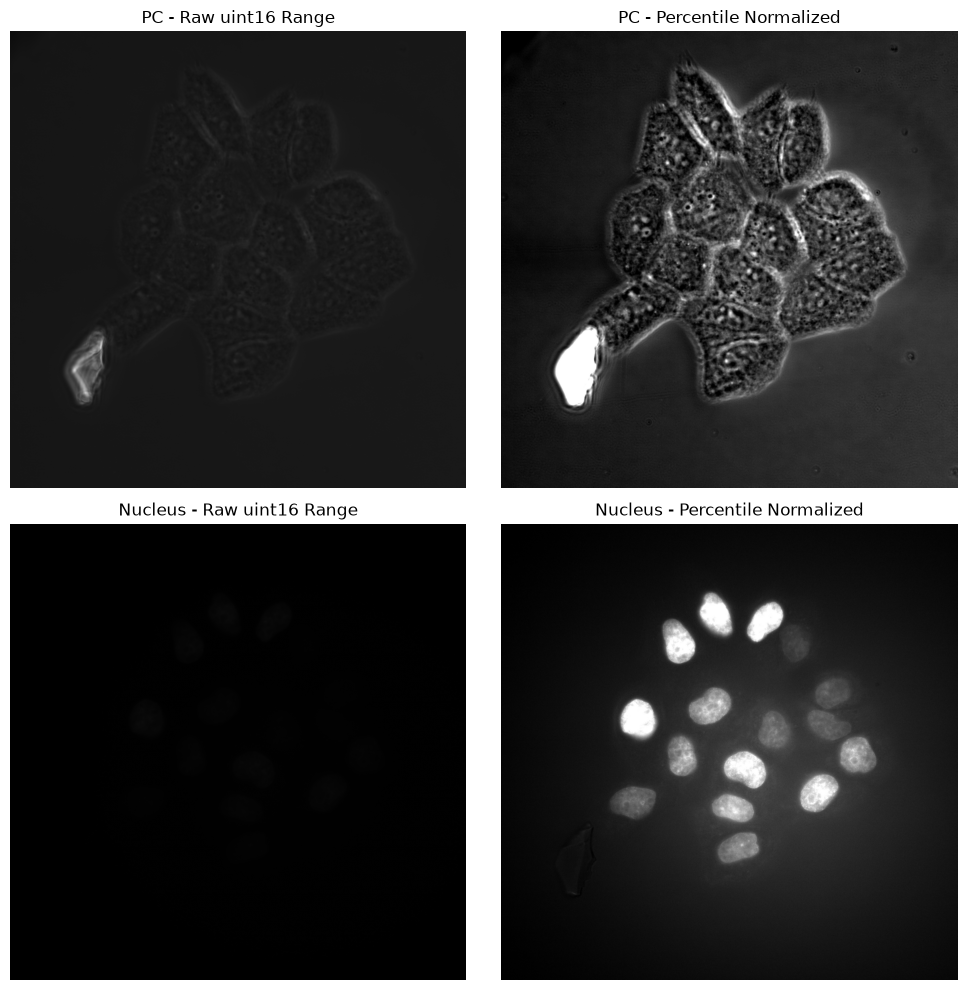

In [7]:
pc_norm = percentile_normalize(pc)
nucleus_norm = percentile_normalize(nucleus)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

axes[0, 0].imshow(pc, cmap="gray", vmin=0, vmax=65535)
axes[0, 0].set_title("PC - Raw uint16 Range")

axes[0, 1].imshow(pc_norm, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title("PC - Percentile Normalized")

axes[1, 0].imshow(nucleus, cmap="gray", vmin=0, vmax=65535)
axes[1, 0].set_title("Nucleus - Raw uint16 Range")

axes[1, 1].imshow(nucleus_norm, cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title("Nucleus - Percentile Normalized")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

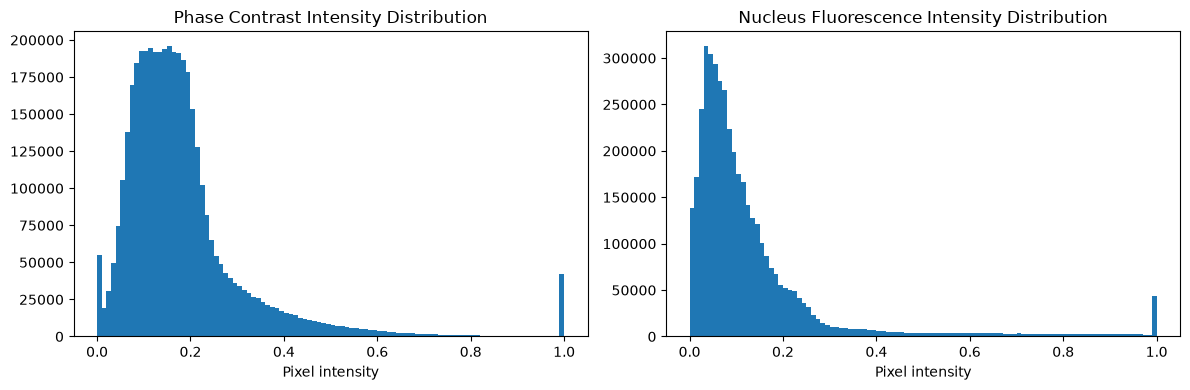

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(pc_norm.ravel(), bins=100)
axes[0].set_title("Phase Contrast Intensity Distribution")
axes[0].set_xlabel("Pixel intensity")

axes[1].hist(nucleus_norm.ravel(), bins=100)
axes[1].set_title("Nucleus Fluorescence Intensity Distribution")
axes[1].set_xlabel("Pixel intensity")

plt.tight_layout()
plt.show()

In [9]:
import json
import pandas as pd

with open("data/metadata/metadata.json") as f:
    metadata = json.load(f)

records = []

for section in metadata["section"]["subsections"]:
    if section["type"] == "Study Component":
        attributes = {
            attr["name"]: attr.get("value")
            for attr in section["attributes"]
        }

        records.append({
            "study": attributes.get("Name"),
            "filelist": attributes.get("File List")
        })

studies_df = pd.DataFrame(records)

display(studies_df)
print("Total studies:", len(studies_df))

,study,filelist
0,Scan Hela H2B GFP,FileList/Study_28.json
1,HeLa Schaffner,FileList/Study_16.json
2,HeLa Vienna,FileList/Study_17.json
3,Human prostate cancer (BF),FileList/Study_11.json
4,Human Prostate Cancer (PC),FileList/Study_12.json
5,U2OS,FileList/Study_1.json
6,Human Liver Carcinoma (BF),FileList/Study_14.json
7,Human Liver Carcinoma,FileList/Study_8.json
8,Human Liver Carcinoma (PC),FileList/Study_15.json
9,Urinary bladder transitional cell carcinoma (BF),FileList/Study_10.json


Total studies: 30


In [10]:
import pandas as pd

df = pd.read_csv("data/metadata/data_z_correspondence.csv")
df.columns = df.columns.str.strip()
df["Publish Filename"] = df["Publish Filename"].str.strip()

df["image_id"] = df["Publish Filename"].str.extract(
    r"image_(\d+)_"
).astype(int)

inputs = df[df["channel"].isin(["BF", "PC", "DIC"])]
targets = df[df["channel"] == "Nucleus"]

records = []

for (study, image_id), target_group in targets.groupby(
    ["Study Number", "image_id"]
):
    candidates = inputs[
        (inputs["Study Number"] == study) &
        (inputs["image_id"] == image_id)
    ]

    focused = candidates[
        candidates["image z"] == candidates["best z focus"]
    ]

    target = target_group.iloc[0]

    if len(focused) == 1:
        selected = focused.iloc[0]
        method = "metadata_focus"
    elif len(focused) > 1:
        distance = (focused["image z"] - target["image z"]).abs()
        selected = focused.loc[distance.idxmin()]
        method = "nearest_target_z"
    else:
        continue

    records.append({
        "study": study,
        "image_id": image_id,
        "modality": selected["channel"],
        "input_file": selected["Publish Filename"],
        "target_file": target["Publish Filename"],
        "input_z": selected["image z"],
        "target_z": target["image z"],
        "selection_method": method
    })

pairs = pd.DataFrame(records)

display(pairs.head())
print("Total matched pairs:", len(pairs))

,study,image_id,modality,input_file,target_file,input_z,target_z,selection_method
0,1,0,BF,image_0_BF_z0.ome.tiff,image_0_Nucleus.ome.tiff,0.0,0.0,metadata_focus
1,1,1,BF,image_1_BF_z0.ome.tiff,image_1_Nucleus.ome.tiff,0.0,0.0,metadata_focus
2,1,2,BF,image_2_BF_z0.ome.tiff,image_2_Nucleus.ome.tiff,0.0,0.0,metadata_focus
3,1,3,BF,image_3_BF_z0.ome.tiff,image_3_Nucleus.ome.tiff,0.0,0.0,metadata_focus
4,1,4,BF,image_4_BF_z0.ome.tiff,image_4_Nucleus.ome.tiff,0.0,0.0,metadata_focus


Total matched pairs: 2533


In [11]:
study_summary = (
    pairs.groupby(["study", "modality"])
    .size()
    .reset_index(name="pairs")
    .sort_values("pairs", ascending=False)
)

display(study_summary)

print("\nPairs by modality:")
print(pairs["modality"].value_counts())

print("\nFocus selection methods:")
print(pairs["selection_method"].value_counts())

,study,modality,pairs
23,25,BF,1289
24,26,BF,587
25,27,PC,197
27,29,PC,48
0,1,BF,43
15,17,DIC,41
3,4,DIC,31
28,30,BF,24
18,20,DIC,23
16,18,DIC,23



Pairs by modality:
modality
BF     1987
PC      293
DIC     253
Name: count, dtype: int64

Focus selection methods:
selection_method
metadata_focus      2525
nearest_target_z       8
Name: count, dtype: int64


In [12]:
from pathlib import Path

output = Path("data/metadata/all_pairs.csv")
output.parent.mkdir(parents=True, exist_ok=True)

assert not pairs.duplicated(["study", "image_id"]).any()
assert len(pairs) == len(targets)

pairs.to_csv(output, index=False)

print("Manifest saved:", output)

Manifest saved: data/metadata/all_pairs.csv


In [13]:
sample_pairs = (
    pairs.groupby("study", group_keys=False)
    .sample(frac=1, random_state=42)
    .groupby("study", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)

print("Selected pairs:", len(sample_pairs))
print("Studies represented:", sample_pairs["study"].nunique())

display(sample_pairs.head())

Selected pairs: 143
Studies represented: 29


,study,image_id,modality,input_file,target_file,input_z,target_z,selection_method
0,1,37,BF,image_37_BF_z0.ome.tiff,image_37_Nucleus.ome.tiff,0.0,0.0,metadata_focus
1,1,24,BF,image_24_BF_z0.ome.tiff,image_24_Nucleus.ome.tiff,0.0,0.0,metadata_focus
2,1,25,BF,image_25_BF_z0.ome.tiff,image_25_Nucleus.ome.tiff,0.0,0.0,metadata_focus
3,1,36,BF,image_36_BF_z0.ome.tiff,image_36_Nucleus.ome.tiff,0.0,0.0,metadata_focus
4,1,34,BF,image_34_BF_z0.ome.tiff,image_34_Nucleus.ome.tiff,0.0,0.0,metadata_focus


In [15]:
from pathlib import Path
import requests
import time

BASE_URL = (
    "https://ftp.ebi.ac.uk/biostudies/fire/"
    "S-BIAD/047/S-BIAD1047/Files/Images"
)

RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

session = requests.Session()

failed = []

for i, row in enumerate(pairs.itertuples(index=False), start=1):
    study_dir = RAW_DIR / f"Study_{row.study}"
    study_dir.mkdir(parents=True, exist_ok=True)

    for filename in (row.input_file, row.target_file):
        destination = study_dir / filename
        temporary = destination.with_name(destination.name + ".part")

        if destination.exists() and destination.stat().st_size > 0:
            continue

        url = f"{BASE_URL}/Study_{row.study}/{filename}"

        for attempt in range(3):
            try:
                with session.get(
                    url, stream=True, timeout=(15, 120)
                ) as response:
                    response.raise_for_status()

                    with open(temporary, "wb") as f:
                        for chunk in response.iter_content(1024 * 1024):
                            if chunk:
                                f.write(chunk)

                temporary.replace(destination)
                break

            except (requests.RequestException, OSError) as e:
                temporary.unlink(missing_ok=True)

                if attempt == 2:
                    failed.append((row.study, filename, str(e)))
                else:
                    time.sleep(2 ** attempt)

    if i % 50 == 0:
        print(f"Processed {i}/{len(pairs)} pairs")

print("Download process finished.")
print("Failed files:", len(failed))

Processed 50/2533 pairs
Processed 100/2533 pairs
Processed 150/2533 pairs
Processed 200/2533 pairs
Processed 250/2533 pairs
Processed 300/2533 pairs
Processed 350/2533 pairs
Processed 400/2533 pairs
Processed 450/2533 pairs
Processed 500/2533 pairs
Processed 550/2533 pairs
Processed 600/2533 pairs
Processed 650/2533 pairs
Processed 700/2533 pairs
Processed 750/2533 pairs
Processed 800/2533 pairs
Processed 850/2533 pairs
Processed 900/2533 pairs
Processed 950/2533 pairs
Processed 1000/2533 pairs
Processed 1050/2533 pairs
Processed 1100/2533 pairs
Processed 1150/2533 pairs
Processed 1200/2533 pairs
Processed 1250/2533 pairs
Processed 1300/2533 pairs
Processed 1350/2533 pairs
Processed 1400/2533 pairs
Processed 1450/2533 pairs
Processed 1500/2533 pairs
Processed 1550/2533 pairs
Processed 1600/2533 pairs
Processed 1650/2533 pairs
Processed 1700/2533 pairs
Processed 1750/2533 pairs
Processed 1800/2533 pairs
Processed 1850/2533 pairs
Processed 1900/2533 pairs
Processed 1950/2533 pairs
Proces

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np
import tifffile

RAW_DIR = Path("data/raw")

results = []

for row in pairs.itertuples(index=False):
    input_path = RAW_DIR / f"Study_{row.study}" / row.input_file
    target_path = RAW_DIR / f"Study_{row.study}" / row.target_file

    record = {
        "study": row.study,
        "image_id": row.image_id,
        "status": "OK",
        "input_shape": None,
        "target_shape": None,
        "error": None
    }

    if not input_path.is_file() or not target_path.is_file():
        record["status"] = "MISSING"
        results.append(record)
        continue

    try:
        with tifffile.TiffFile(input_path) as tif:
            x = tif.asarray()

        with tifffile.TiffFile(target_path) as tif:
            y = tif.asarray()

        record["input_shape"] = x.shape
        record["target_shape"] = y.shape

        if x.shape != y.shape:
            record["status"] = "SHAPE_MISMATCH"
        elif x.ndim != 2 or y.ndim != 2:
            record["status"] = "UNEXPECTED_DIMENSIONS"
        elif not np.isfinite(x).all() or not np.isfinite(y).all():
            record["status"] = "INVALID_VALUES"
        elif x.min() == x.max() or y.min() == y.max():
            record["status"] = "CONSTANT_IMAGE"

    except Exception as e:
        record["status"] = "READ_ERROR"
        record["error"] = str(e)

    results.append(record)

validation_df = pd.DataFrame(results)

print(validation_df["status"].value_counts())
display(validation_df[validation_df["status"] != "OK"].head(20))

status
OK                2532
CONSTANT_IMAGE       1
Name: count, dtype: int64


,study,image_id,status,input_shape,target_shape,error
2501,29,2542,CONSTANT_IMAGE,"(2048, 2048)","(2048, 2048)",None


In [18]:
import requests
import tifffile
from pathlib import Path

BASE_URL = (
    "https://ftp.ebi.ac.uk/biostudies/fire/"
    "S-BIAD/047/S-BIAD1047/Files/Images"
)

bad_pairs = validation_df[validation_df["status"] == "READ_ERROR"]

with requests.Session() as session:
    for bad in bad_pairs.itertuples(index=False):
        row = pairs[
            (pairs["study"] == bad.study) &
            (pairs["image_id"] == bad.image_id)
        ].iloc[0]

        folder = Path(RAW_DIR) / f"Study_{bad.study}"

        for filename in [row["input_file"], row["target_file"]]:
            path = folder / filename

            try:
                tifffile.imread(path)
                continue  # This file is healthy
            except Exception:
                print(f"Corrupted: {filename}")

            url = f"{BASE_URL}/Study_{bad.study}/{filename}"
            temp = path.with_name(path.name + ".part")

            try:
                with session.get(url, stream=True, timeout=(15, 120)) as response:
                    response.raise_for_status()

                    with open(temp, "wb") as f:
                        for chunk in response.iter_content(1024 * 1024):
                            if chunk:
                                f.write(chunk)

                # Verify the new file before replacing the original
                tifffile.imread(temp)
                temp.replace(path)
                print(f"Repaired: {filename}")

            except Exception as e:
                temp.unlink(missing_ok=True)
                print(f"FAILED: {filename} — {e}")

Corrupted: image_1380_Nucleus.ome.tiff
Repaired: image_1380_Nucleus.ome.tiff
Corrupted: image_1675_BF_z9.ome.tiff
Repaired: image_1675_BF_z9.ome.tiff
Corrupted: image_2126_BF_z13.ome.tiff
Repaired: image_2126_BF_z13.ome.tiff
Corrupted: image_2159_Nucleus.ome.tiff
Repaired: image_2159_Nucleus.ome.tiff


In [20]:
row = pairs[
    (pairs["study"] == 29) &
    (pairs["image_id"] == 2542)
].iloc[0]

folder = RAW_DIR / "Study_29"

for channel, filename in [
    ("Input", row["input_file"]),
    ("Target", row["target_file"])
]:
    image = tifffile.imread(folder / filename)

    print(
        channel,
        "min:", image.min(),
        "max:", image.max(),
        "std:", image.std(),
        "unique:", len(np.unique(image))
    )

Input min: 0 max: 0 std: 0.0 unique: 1
Target min: 46 max: 23421 std: 784.333886261352 unique: 13590
